# Customer-Level RFM Segmentation

This notebook rebuilds the RFM analysis **per customer** (`user_id`). The earlier notebook grouped by `product_id`, which segments products rather than customers. All logic lives in `src/rfm.py` so it can be tested and reused; this notebook calls it and draws the charts.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
import matplotlib.pyplot as plt
from src.rfm import load_transactions, build_rfm, score_rfm, assign_segments, segment_summary

DATA = ROOT / 'Transaction_Cleaned_Data (1).csv'
IMAGES = ROOT / 'images'
IMAGES.mkdir(exist_ok=True)

## 1. Load the cleaned transactions

In [2]:
tx = load_transactions(DATA)
print(f"{len(tx):,} line items · {tx.order_id.nunique():,} orders · {tx.user_id.nunique():,} customers")
print(f"Window: {tx.event_time.min():%d %b %Y} to {tx.event_time.max():%d %b %Y}")
print(f"Revenue: {tx.price.sum():,.0f}")

21,860 line items · 17,934 orders · 12,926 customers
Window: 24 Apr 2020 to 11 Jun 2020
Revenue: 3,867,198


## 2. Build and score RFM per customer

- **Recency:** days from the customer's last purchase to the day after the last transaction in the data.
- **Frequency:** distinct orders (not line items).
- **Monetary:** total spend.

R and M are scored 1 to 4 by quartile. Frequency is scored by fixed cut-offs (1, 2, 3, 4+ orders) because most customers order once, so frequency quartiles would collapse.

In [3]:
rfm = build_rfm(tx)
scored = score_rfm(rfm)
print(rfm.describe().round(1))
print('\nOrders per customer:')
print(rfm.frequency.clip(upper=5).value_counts().sort_index().rename({5: '5+'}))

       recency  frequency  monetary
count  12926.0    12926.0   12926.0
mean      22.9        1.4     299.2
std       11.7        1.4     590.1
min        0.0        1.0       0.0
25%       15.0        1.0      37.0
50%       23.0        1.0     122.7
75%       33.0        1.0     344.2
max       48.0       61.0   15286.2

Orders per customer:
frequency
1     10136
2      1933
3       478
4       162
5+      217
Name: count, dtype: int64


## 3. Segment

Rules are applied in order and the first match wins, so every customer belongs to exactly one segment. See `SEGMENT_RULES` in `src/rfm.py`.

In [4]:
seg = assign_segments(scored)
summary = segment_summary(seg)
assert seg.index.is_unique and seg.segment.notna().all()
summary

,customers,revenue,avg_recency_days,avg_orders,avg_spend,customer_share_pct,revenue_share_pct
segment,,,,,,,
Champions,668,845933.3,12.3,4.9,1266.4,5.2,21.9
Loyal Customers,1207,561228.0,13.0,2.0,465.0,9.3,14.5
At Risk Repeat Buyers,915,399597.6,31.7,2.3,436.7,7.1,10.3
New High-Value,1004,431477.0,7.1,1.0,429.8,7.8,11.2
New Customers,1272,59092.7,7.4,1.0,46.5,9.8,1.5
Promising,2312,586973.7,18.7,1.0,253.9,17.9,15.2
Big Spenders Slipping,863,566023.6,32.9,1.0,655.9,6.7,14.6
Hibernating,2281,212260.8,28.1,1.0,93.1,17.6,5.5
Lost,2404,204610.9,37.9,1.0,85.1,18.6,5.3


## 4. Customer share vs revenue share

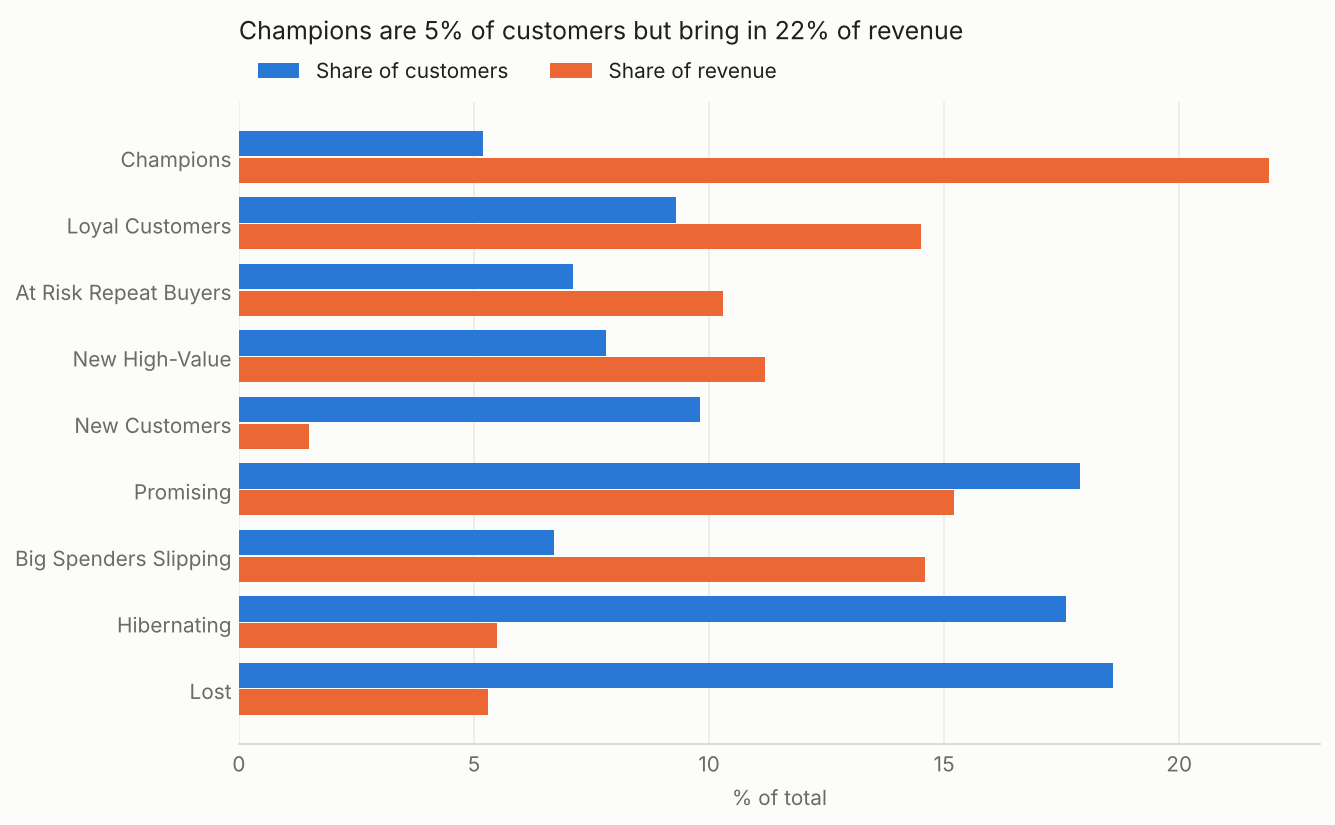

In [5]:
BLUE, ORANGE, INK, MUTED, SURFACE = "#2a78d6", "#eb6834", "#1f1f1e", "#6b6a64", "#fcfcfb"
s = summary.iloc[::-1]
y = range(len(s)); h = 0.38
fig, ax = plt.subplots(figsize=(9, 5.6), dpi=150, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.barh([i + h/2 + 0.01 for i in y], s.customer_share_pct, height=h, color=BLUE, label="Share of customers")
ax.barh([i - h/2 - 0.01 for i in y], s.revenue_share_pct, height=h, color=ORANGE, label="Share of revenue")
ax.set_yticks(list(y), s.index, color=INK)
ax.set_xlabel("% of total", color=MUTED)
for spine in ["top", "right", "left"]:
    ax.spines[spine].set_visible(False)
ax.spines["bottom"].set_color("#d6d5ce")
ax.tick_params(colors=MUTED, length=0)
ax.xaxis.grid(True, color="#ecebe6"); ax.set_axisbelow(True)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=INK)
ax.set_title("Champions are 5% of customers but bring in 22% of revenue", loc="left", color=INK, fontsize=12, pad=30)
fig.tight_layout()
fig.savefig(IMAGES / "segment_share.png", facecolor=SURFACE)
plt.show()

## 5. How concentrated is revenue?

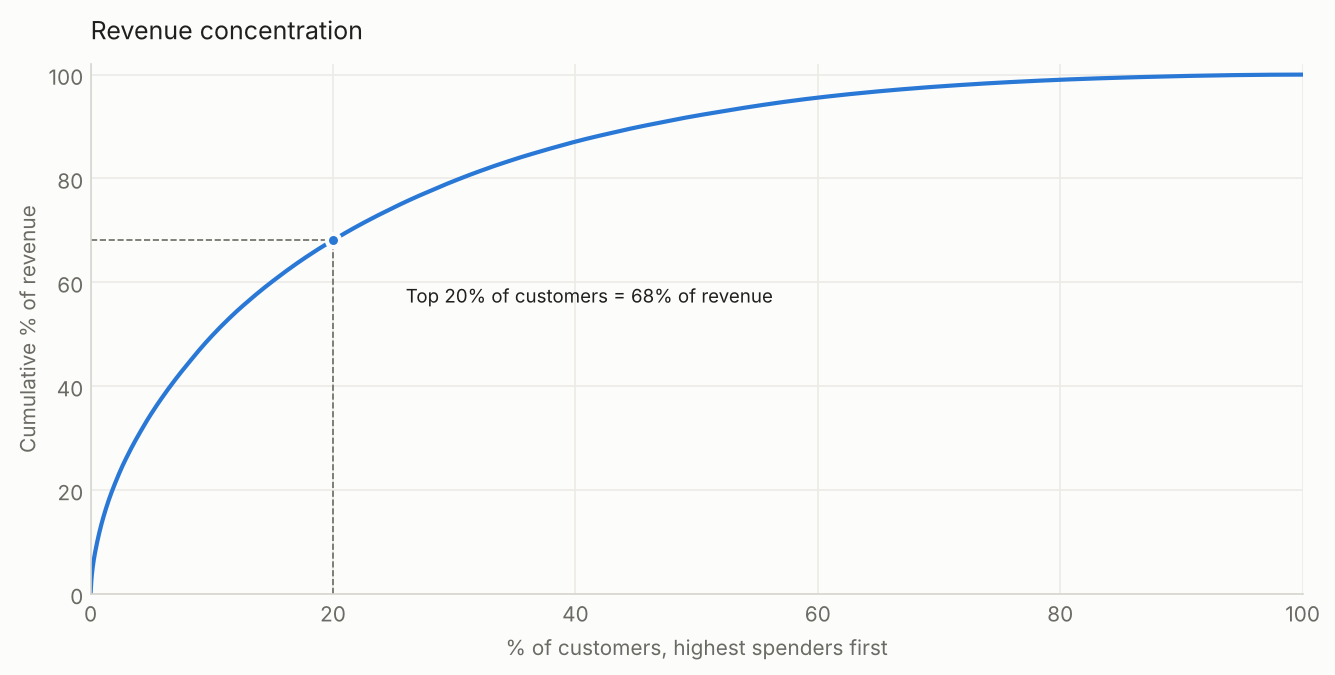

Top 20% of customers: 68.1% of revenue


In [6]:
spend = rfm.monetary.sort_values(ascending=False).reset_index(drop=True)
cum = 100 * spend.cumsum() / spend.sum()
pct_customers = 100 * (spend.index + 1) / len(spend)
top20 = cum[pct_customers <= 20].iloc[-1]
fig, ax = plt.subplots(figsize=(9, 4.6), dpi=150, facecolor=SURFACE)
ax.set_facecolor(SURFACE)
ax.plot(pct_customers, cum, color=BLUE, lw=2)
ax.plot([20, 20], [0, top20], color=MUTED, lw=0.8, ls="--")
ax.plot([0, 20], [top20, top20], color=MUTED, lw=0.8, ls="--")
ax.scatter([20], [top20], s=40, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=3)
ax.annotate(f"Top 20% of customers = {top20:.0f}% of revenue", xy=(20, top20), xytext=(26, top20 - 12), color=INK, fontsize=9)
ax.set_xlim(0, 100); ax.set_ylim(0, 102)
ax.set_xlabel("% of customers, highest spenders first", color=MUTED)
ax.set_ylabel("Cumulative % of revenue", color=MUTED)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
for spine in ["left", "bottom"]:
    ax.spines[spine].set_color("#d6d5ce")
ax.tick_params(colors=MUTED, length=0)
ax.grid(True, color="#ecebe6"); ax.set_axisbelow(True)
ax.set_title("Revenue concentration", loc="left", color=INK, fontsize=12, pad=12)
fig.tight_layout()
fig.savefig(IMAGES / "revenue_concentration.png", facecolor=SURFACE)
plt.show()
print(f"Top 20% of customers: {top20:.1f}% of revenue")

## 6. Export

One row per customer with R, F, M scores, the RFM code and the segment, ready for a CRM or a BI dashboard.

In [7]:
out = ROOT / 'outputs'
out.mkdir(exist_ok=True)
seg.to_csv(out / 'customer_segments.csv')
summary.to_csv(out / 'segment_summary.csv')
print(f"Wrote {len(seg):,} customers")

Wrote 12,926 customers
